In [1]:
# Importing libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#Load the dataset

ai_impact=pd.read_csv("ai_student_impact_dataset (1).csv")
ai_impact

,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,149996,Business,Senior,2.899,12.16,Copywriting/Drafting,Beginner,2,False,13.36,2,Allowed_With_Citation,2,3.584
49996,149997,STEM,Senior,2.870,2.51,Copywriting/Drafting,Intermediate,1,False,4.67,3,Actively_Encouraged,3,3.096
49997,149998,Business,Senior,3.177,15.87,Summarizing_Reading,Advanced,5,True,3.92,4,Allowed_With_Citation,5,3.605
49998,149999,Business,Junior,3.398,19.91,Debugging/Troubleshooting,Intermediate,5,False,7.10,5,Allowed_With_Citation,3,3.527


In [3]:
#Creating a function for Descriptive Statistics
def desc_stat(ds,var):
    Average=ds[var].mean()
    median_=ds[var].median()
    mode_=ds[var].mode()
    minimum=ds[var].min()
    maximum=ds[var].max()
    range_=ds[var].max()-ds[var].min()
    standard_dev=ds[var].std()
    variance=ds[var].var()
    skew=ds[var].skew()
    kurt=ds[var].kurt()
    count_=ds[var].count()
    q1=ds[var].quantile(0.25)
    q2=ds[var].quantile(0.50)
    q3=ds[var].quantile(0.75)
    iqr=ds[var].quantile(0.75)-ds[var].quantile(0.25)

    descriptive={
        'Mean': Average,
        'Median': median_,
        'Mode': mode_,
        'Minimum': minimum,
        'Maximum': maximum,
        'Range': range_,
        'Standard Deviation': standard_dev,
        'Variance': variance,
        'Skewness': skew,
        'Kurtosis': kurt,
        'Count': count_,
        'Q1 25%': q1,
        'Q2 50%': q2,
        'Q3 75%': q3,
        'IQR': iqr
    }
    return descriptive

In [4]:
#Random Sampling

sample_size=150
sample=ai_impact.sample(n=sample_size, replace=False, random_state=42)

#Applying Descriptive statistics to the column Post GPA

desc=desc_stat(sample,'Post_Semester_GPA')
desc

{'Mean': np.float64(3.3309733333333336),
 'Median': np.float64(3.347),
 'Mode': 0    4.0
 Name: Post_Semester_GPA, dtype: float64,
 'Minimum': np.float64(2.106),
 'Maximum': np.float64(4.0),
 'Range': np.float64(1.8940000000000001),
 'Standard Deviation': np.float64(0.49216152402140234),
 'Variance': np.float64(0.2422229657270694),
 'Skewness': np.float64(-0.39055338417291147),
 'Kurtosis': np.float64(-0.8032576291014202),
 'Count': np.int64(150),
 'Q1 25%': np.float64(2.97325),
 'Q2 50%': np.float64(3.347),
 'Q3 75%': np.float64(3.75225),
 'IQR': np.float64(0.7789999999999999)}

In [5]:
#Systamatic Sampling - Students who use AI more than 10 hours 

syst_sample=ai_impact[ai_impact['Weekly_GenAI_Hours']>10]
desc2=desc_stat(syst_sample,'Post_Semester_GPA')
desc2

{'Mean': np.float64(3.342553659337053),
 'Median': np.float64(3.414),
 'Mode': 0    4.0
 Name: Post_Semester_GPA, dtype: float64,
 'Minimum': np.float64(1.0),
 'Maximum': np.float64(4.0),
 'Range': np.float64(3.0),
 'Standard Deviation': np.float64(0.5026161038073215),
 'Variance': np.float64(0.25262294780645217),
 'Skewness': np.float64(-0.6607682255513981),
 'Kurtosis': np.float64(-0.08411404221022778),
 'Count': np.int64(15235),
 'Q1 25%': np.float64(3.012),
 'Q2 50%': np.float64(3.414),
 'Q3 75%': np.float64(3.7495000000000003),
 'IQR': np.float64(0.7375000000000003)}

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns


Text(0, 0.5, 'Post Semester GPA')

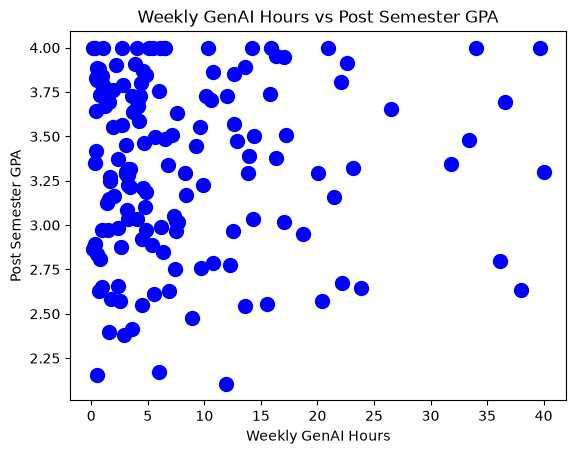

In [7]:
#Graphs

# Scatter plot: AI hours and GPA
plt.scatter(x=sample['Weekly_GenAI_Hours'], y=sample['Post_Semester_GPA'], s=100, c='blue')
plt.title('Weekly GenAI Hours vs Post Semester GPA')
plt.xlabel('Weekly GenAI Hours')
plt.ylabel('Post Semester GPA')


In [8]:
plt.show()

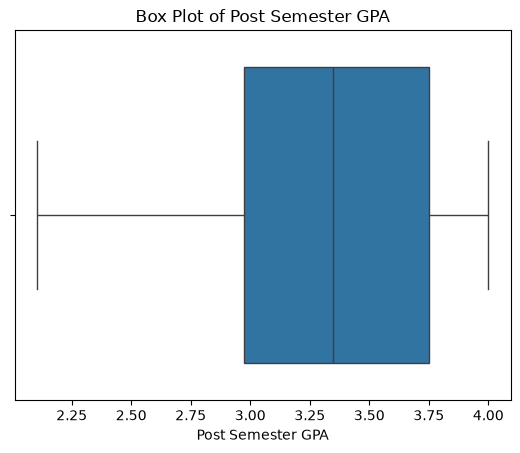

In [9]:
# Box Plot

import seaborn as sns

sns.boxplot(x=sample['Post_Semester_GPA'])

plt.xlabel('Post Semester GPA')
plt.title('Box Plot of Post Semester GPA')

plt.show()

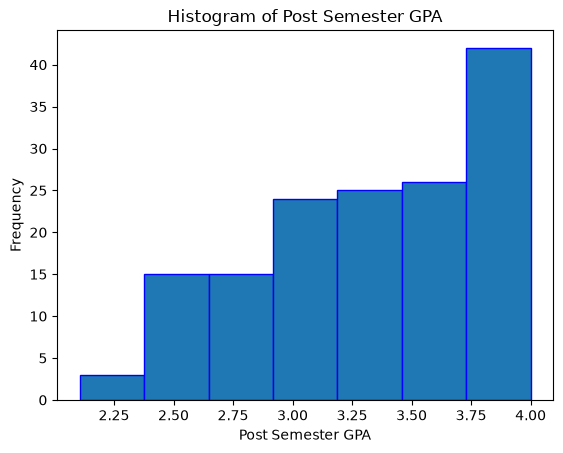

In [10]:
#Histogram
plt.hist(sample['Post_Semester_GPA'], bins=7, edgecolor='blue')

plt.xlabel('Post Semester GPA')
plt.ylabel('Frequency')
plt.title('Histogram of Post Semester GPA')

plt.show()

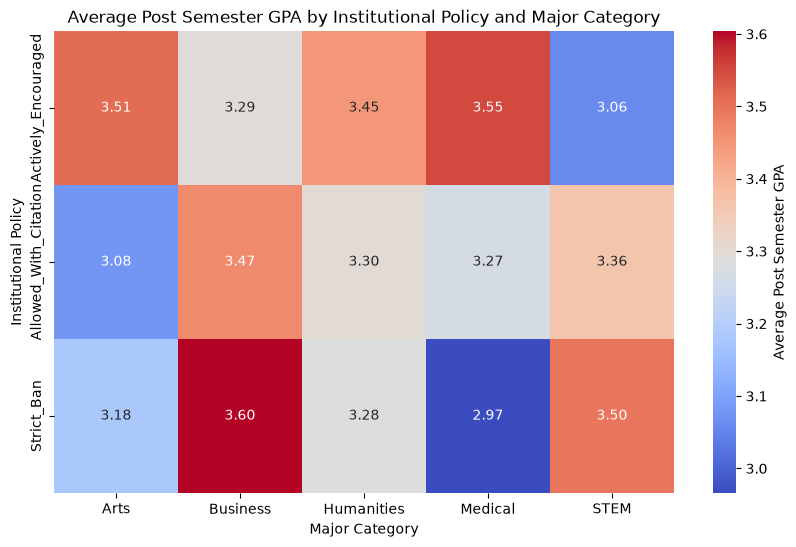

In [11]:
heatmap_data = sample.pivot_table(
    index='Institutional_Policy',
    columns='Major_Category',
    values='Post_Semester_GPA',
    aggfunc='mean'
)

plt.figure(figsize=(10, 6))
sns.heatmap(heatmap_data, annot=True, fmt=".2f", cmap="coolwarm", cbar_kws={'label': 'Average Post Semester GPA'})
plt.title('Average Post Semester GPA by Institutional Policy and Major Category')
plt.ylabel('Institutional Policy')
plt.xlabel('Major Category')
plt.show()

In [12]:
import pandas as pd

contingency_data = pd.crosstab(sample['Institutional_Policy'], sample['Major_Category'])

#checking chi-square for cross tab
from scipy.stats import chi2_contingency
r, p, dof, expected = chi2_contingency(contingency_data)
print('r=%.3f, p=%.3f' % (r, p))
if p > 0.05:
    print('independent categories')
else:
    print('dependent categories')

r=5.252, p=0.730
independent categories


In [13]:
#Pearson Hypothesis Test
from scipy.stats import pearsonr

data = sample[['Weekly_GenAI_Hours', 'Post_Semester_GPA']].dropna()

r_value, p_value = pearsonr(data['Weekly_GenAI_Hours'], data['Post_Semester_GPA'])
degrees_of_freedom = len(data) - 2

print(f"Pearson Correlation Coefficient (r): {r_value:.3f}")
print(f"P-Value: {p_value:.3f}")
print(f"Degrees of Freedom: {degrees_of_freedom}")

if p_value < 0.05:
    print("Conclusion: Since the p-value is less than 0.05, we reject the null hypothesis.")
    print("There is a statistically significant correlation between Weekly GenAI Hours and Post Semester GPA.")
else:
    print("Conclusion: Since the p-value is greater than 0.05, we fail to reject the null hypothesis.")
    print("There is no statistically significant correlation between Weekly GenAI Hours and Post Semester GPA.")

Pearson Correlation Coefficient (r): 0.035
P-Value: 0.667
Degrees of Freedom: 148
Conclusion: Since the p-value is greater than 0.05, we fail to reject the null hypothesis.
There is no statistically significant correlation between Weekly GenAI Hours and Post Semester GPA.


In [14]:
#Spearman Hypothesis Test
from scipy.stats import spearmanr

r, p_value = spearmanr(data['Weekly_GenAI_Hours'], data['Post_Semester_GPA'])
df_spearman = len(data) - 2

print("Spearman's Correlation Test Results:")
print(f"Spearman's Correlation Coefficient (r): {r:.4f}")
print(f"P-Value: {p_value:.4f}")
print(f"Degrees of Freedom: {df_spearman}")

if p_value < 0.05:
    print("\nConclusion: Since the p-value is less than 0.05, we reject the null hypothesis.")
    print("There is a statistically significant correlation between Weekly GenAI Hours and Post Semester GPA.")
else:
    print("\nConclusion: Since the p-value is greater than 0.05, we fail to reject the null hypothesis.")
    print("There is no statistically significant correlation between Weekly GenAI Hours and Post Semester GPA.")

Spearman's Correlation Test Results:
Spearman's Correlation Coefficient (r): 0.0225
P-Value: 0.7843
Degrees of Freedom: 148

Conclusion: Since the p-value is greater than 0.05, we fail to reject the null hypothesis.
There is no statistically significant correlation between Weekly GenAI Hours and Post Semester GPA.


In [15]:
#Finding the average of Post Semester GPA of all the students
GPA = ai_impact['Post_Semester_GPA']
print(GPA.mean())

# Extracting Post Semester GPA of the random sample
GPA_sample = sample['Post_Semester_GPA']

#Checking for normality
from scipy.stats import shapiro
r, p = shapiro(GPA_sample)
print('r=%.2f, p=%.6f' % (r, p))
if p > 0.05:
    print('Normal distribution')
else:
    print('Not a normal distribution')

#One Sample T-test
import scipy
scipy.stats.ttest_1samp(GPA_sample, GPA.mean())

3.3492994200000004
r=0.95, p=0.000035
Not a normal distribution


TtestResult(statistic=np.float64(-0.45604500884758103), pvalue=np.float64(0.6490216033435183), df=np.int64(149))

In [16]:
sample

,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA
33553,133554,STEM,Graduate,2.208,1.75,Direct_Answer_Generation,Intermediate,1,True,8.22,2,Actively_Encouraged,2,2.582
9427,109428,Arts,Graduate,2.931,3.08,Ideation,Beginner,3,True,11.68,5,Actively_Encouraged,8,3.452
199,100200,Arts,Sophomore,2.874,14.28,Direct_Answer_Generation,Advanced,3,False,13.68,6,Strict_Ban,5,3.035
12447,112448,Medical,Junior,2.517,7.42,Copywriting/Drafting,Beginner,1,True,1.00,1,Allowed_With_Citation,1,2.754
39489,139490,Business,Sophomore,2.927,3.12,Copywriting/Drafting,Intermediate,3,False,5.59,3,Actively_Encouraged,4,3.084
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21802,121803,Humanities,Junior,3.366,0.46,Copywriting/Drafting,Intermediate,1,False,8.35,6,Allowed_With_Citation,3,3.827
41163,141164,Medical,Graduate,3.679,2.77,Summarizing_Reading,Advanced,4,True,12.63,4,Allowed_With_Citation,3,3.792
6232,106233,Business,Graduate,3.392,0.54,Summarizing_Reading,Advanced,4,False,16.90,5,Allowed_With_Citation,4,3.888
3862,103863,Humanities,Graduate,2.510,0.70,Copywriting/Drafting,Beginner,1,False,3.98,3,Allowed_With_Citation,4,2.631


In [17]:
ai_impact.isnull().sum()

Student_ID                    0
Major_Category                0
Year_of_Study                 0
Pre_Semester_GPA              0
Weekly_GenAI_Hours            0
Primary_Use_Case              0
Prompt_Engineering_Skill      0
Tool_Diversity                0
Paid_Subscription             0
Traditional_Study_Hours       0
Perceived_AI_Dependency       0
Institutional_Policy          0
Anxiety_Level_During_Exams    0
Post_Semester_GPA             0
dtype: int64

In [18]:
ai_impact.duplicated().sum()

np.int64(0)

In [19]:
ai_impact = ai_impact.drop(columns=['Student_ID'])

In [20]:
# Independent numeric variables to check
ind_numeric = ['Pre_Semester_GPA', 'Weekly_GenAI_Hours', 'Traditional_Study_Hours',
               'Anxiety_Level_During_Exams', 'Tool_Diversity', 'Perceived_AI_Dependency']

outlier_list = []      # empty list to collect the outlier rows of each variable

for col in ind_numeric:
    q1 = ai_impact[col].quantile(0.25)
    q3 = ai_impact[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    outliers = ai_impact[(ai_impact[col] < low) | (ai_impact[col] > high)]   # rows outside the limits
    print(col, "-> outliers:", len(outliers))
    outlier_list.append(outliers)

    # Combine all outliers into one DataFrame and remove duplicates
all_outliers = pd.concat(outlier_list)
all_outliers = all_outliers[~all_outliers.index.duplicated()]   # a student counted once
print("Total outlier rows:", len(all_outliers))

# Remove the outlier rows from the dataset
ai_impact = ai_impact.drop(all_outliers.index).reset_index(drop=True)
print("Shape after removal:", ai_impact.shape)

Pre_Semester_GPA -> outliers: 328
Weekly_GenAI_Hours -> outliers: 2583
Traditional_Study_Hours -> outliers: 161
Anxiety_Level_During_Exams -> outliers: 0
Tool_Diversity -> outliers: 0
Perceived_AI_Dependency -> outliers: 190
Total outlier rows: 3057
Shape after removal: (46943, 13)


In [21]:
x_indep = ai_impact.iloc[:, 0:12]
y_dep = ai_impact.iloc[:, 12]

In [22]:
y_dep

0        2.393
1        3.696
2        3.499
3        4.000
4        3.798
         ...  
46938    3.584
46939    3.096
46940    3.605
46941    3.527
46942    3.261
Name: Post_Semester_GPA, Length: 46943, dtype: float64

In [23]:
x_indep['Year_of_Study'] = x_indep['Year_of_Study'].map(
    {'Freshman': 1, 'Sophomore': 2, 'Junior': 3, 'Senior': 4, 'Graduate': 5})

x_indep['Prompt_Engineering_Skill'] = x_indep['Prompt_Engineering_Skill'].map(
    {'Beginner': 1, 'Intermediate': 2, 'Advanced': 3})

x_indep['Paid_Subscription'] = x_indep['Paid_Subscription'].astype(int)


In [24]:
x_indep = pd.get_dummies(x_indep,
                         columns=['Institutional_Policy', 'Major_Category', 'Primary_Use_Case'],
                         drop_first=True, dtype=int)

In [25]:
x_indep

,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Anxiety_Level_During_Exams,Institutional_Policy_Allowed_With_Citation,Institutional_Policy_Strict_Ban,Major_Category_Business,Major_Category_Humanities,Major_Category_Medical,Major_Category_STEM,Primary_Use_Case_Debugging/Troubleshooting,Primary_Use_Case_Direct_Answer_Generation,Primary_Use_Case_Ideation,Primary_Use_Case_Summarizing_Reading
0,4,2.418,23.31,1,1,1,8.13,5,6,1,0,0,1,0,0,0,0,0,0
1,3,3.821,1.12,3,5,0,16.65,3,9,1,0,0,0,1,0,0,0,1,0
2,1,3.398,21.26,1,2,0,10.35,5,9,0,1,1,0,0,0,0,0,0,1
3,4,3.789,1.82,2,4,0,15.23,2,2,1,0,1,0,0,0,0,0,0,0
4,2,3.635,9.29,3,4,0,12.55,4,4,1,0,0,0,0,1,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46938,4,2.899,12.16,1,2,0,13.36,2,2,1,0,1,0,0,0,0,0,0,0
46939,4,2.870,2.51,2,1,0,4.67,3,3,0,0,0,0,0,1,0,0,0,0
46940,4,3.177,15.87,3,5,1,3.92,4,5,1,0,1,0,0,0,0,0,0,1
46941,3,3.398,19.91,2,5,0,7.10,5,3,1,0,1,0,0,0,1,0,0,0


In [26]:
print(x_indep.head())
print(x_indep.shape)

   Year_of_Study  Pre_Semester_GPA  Weekly_GenAI_Hours  \
0              4             2.418               23.31   
1              3             3.821                1.12   
2              1             3.398               21.26   
3              4             3.789                1.82   
4              2             3.635                9.29   

   Prompt_Engineering_Skill  Tool_Diversity  Paid_Subscription  \
0                         1               1                  1   
1                         3               5                  0   
2                         1               2                  0   
3                         2               4                  0   
4                         3               4                  0   

   Traditional_Study_Hours  Perceived_AI_Dependency  \
0                     8.13                        5   
1                    16.65                        3   
2                    10.35                        5   
3                    15.23        

In [27]:
pd.set_option('display.max_columns', None)
x_indep.head(5).T

,0,1,2,3,4
Year_of_Study,4.000,3.000,1.000,4.000,2.000
Pre_Semester_GPA,2.418,3.821,3.398,3.789,3.635
Weekly_GenAI_Hours,23.310,1.120,21.260,1.820,9.290
Prompt_Engineering_Skill,1.000,3.000,1.000,2.000,3.000
Tool_Diversity,1.000,5.000,2.000,4.000,4.000
Paid_Subscription,1.000,0.000,0.000,0.000,0.000
Traditional_Study_Hours,8.130,16.650,10.350,15.230,12.550
Perceived_AI_Dependency,5.000,3.000,5.000,2.000,4.000
Anxiety_Level_During_Exams,6.000,9.000,9.000,2.000,4.000
Institutional_Policy_Allowed_With_Citation,1.000,1.000,0.000,1.000,1.000


In [28]:
year_map = {'Freshman': 1, 'Sophomore': 2, 'Junior': 3, 'Senior': 4, 'Graduate': 5}
skill_map = {'Beginner': 1, 'Intermediate': 2, 'Advanced': 3}
paid_map = {'False (free)': 0, 'True (paid)': 1}

print("Year_of_Study:", year_map)
print("Prompt_Engineering_Skill:", skill_map)
print("Paid_Subscription:", paid_map)

Year_of_Study: {'Freshman': 1, 'Sophomore': 2, 'Junior': 3, 'Senior': 4, 'Graduate': 5}
Prompt_Engineering_Skill: {'Beginner': 1, 'Intermediate': 2, 'Advanced': 3}
Paid_Subscription: {'False (free)': 0, 'True (paid)': 1}


In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(x_indep, y_dep, test_size=0.2, random_state=42)

In [43]:
print(X_train.shape, X_test.shape)

(37554, 19) (9389, 19)


In [30]:
print(X_train)

       Year_of_Study  Pre_Semester_GPA  Weekly_GenAI_Hours  \
41530              5             3.069                0.21   
2232               2             2.958                0.06   
40712              2             2.767                6.81   
40360              1             3.571                8.39   
9908               4             3.450                2.58   
...              ...               ...                 ...   
11284              4             3.530                0.65   
44732              4             3.141                1.31   
38158              1             3.069               20.78   
860                3             3.167               12.65   
15795              1             3.272               22.83   

       Prompt_Engineering_Skill  Tool_Diversity  Paid_Subscription  \
41530                         1               2                  0   
2232                          3               3                  0   
40712                         2              

In [31]:
print(y_train)

41530    3.054
2232     3.124
40712    3.160
40360    3.638
9908     3.511
         ...  
11284    3.899
44732    3.391
38158    3.335
860      3.091
15795    3.653
Name: Post_Semester_GPA, Length: 37554, dtype: float64


In [32]:
print(X_test)

       Year_of_Study  Pre_Semester_GPA  Weekly_GenAI_Hours  \
8961               5             3.501                0.95   
19497              5             2.022               14.59   
41378              1             2.415                2.19   
23467              1             2.877                3.11   
20788              3             3.358                2.23   
...              ...               ...                 ...   
27804              1             1.888                3.59   
33659              5             3.198               14.07   
41524              5             2.951               21.87   
26032              1             3.293               13.33   
2935               1             3.888                4.55   

       Prompt_Engineering_Skill  Tool_Diversity  Paid_Subscription  \
8961                          1               2                  0   
19497                         2               3                  0   
41378                         1              

In [33]:
print(y_test)

8961     3.639
19497    2.375
41378    2.631
23467    2.756
20788    3.309
         ...  
27804    1.919
33659    3.469
41524    3.599
26032    3.456
2935     3.718
Name: Post_Semester_GPA, Length: 9389, dtype: float64


In [34]:
from sklearn.preprocessing import StandardScaler

# the columns to scale (not the 0/1 columns)
cols = ['Pre_Semester_GPA', 'Weekly_GenAI_Hours', 'Traditional_Study_Hours',
        'Anxiety_Level_During_Exams', 'Tool_Diversity', 'Perceived_AI_Dependency',
        'Year_of_Study', 'Prompt_Engineering_Skill']

sc = StandardScaler()
X_train[cols] = sc.fit_transform(X_train[cols])   # learn from the training data and scale it
X_test[cols] = sc.transform(X_test[cols])         # scale the test data with the same numbers

X_train[cols].describe().round(2)

,Pre_Semester_GPA,Weekly_GenAI_Hours,Traditional_Study_Hours,Anxiety_Level_During_Exams,Tool_Diversity,Perceived_AI_Dependency,Year_of_Study,Prompt_Engineering_Skill
count,37554.00,37554.00,37554.00,37554.00,37554.00,37554.00,37554.00,37554.00
mean,-0.00,0.00,-0.00,-0.00,0.00,0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.91,-1.17,-2.03,-1.52,-1.51,-1.43,-1.37,-1.13
25%,-0.68,-0.80,-0.70,-0.57,-0.67,-0.81,-0.64,-1.13
50%,0.12,-0.28,0.00,-0.09,0.17,-0.19,0.10,0.12
75%,0.79,0.55,0.69,0.86,1.01,0.43,0.83,1.37
max,1.81,3.05,2.79,2.77,1.85,3.52,1.56,1.37


In [57]:
print(X_train.shape, X_test.shape)

(37554, 19) (9389, 19)


In [35]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import PolynomialFeatures
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error

#  Linear
regressor_lin = LinearRegression()
regressor_lin.fit(X_train, y_train)
y_pred_lin = regressor_lin.predict(X_test)

#Polynomial, degree 2
poly_reg = PolynomialFeatures(degree = 2)
X_poly = poly_reg.fit_transform(X_train)
regressor_poly = LinearRegression()
regressor_poly.fit(X_poly, y_train)
y_pred_poly = regressor_poly.predict(poly_reg.transform(X_test))

# Ridge
regressor_ridge = Ridge(alpha = 1.0)
regressor_ridge.fit(X_train, y_train)
y_pred_ridge = regressor_ridge.predict(X_test)

# Lasso
regressor_lasso = Lasso(alpha = 0.001)
regressor_lasso.fit(X_train, y_train)
y_pred_lasso = regressor_lasso.predict(X_test)

# Elastic Net
regressor_enet = ElasticNet(alpha = 0.001, l1_ratio = 0.5)
regressor_enet.fit(X_train, y_train)
y_pred_enet = regressor_enet.predict(X_test)

#  Random Forest
regressor_rf = RandomForestRegressor(n_estimators = 100, random_state = 42)
regressor_rf.fit(X_train, y_train)
y_pred_rf = regressor_rf.predict(X_test)

#  Gradient Boosting
regressor_gb = GradientBoostingRegressor(n_estimators = 100, random_state = 42)
regressor_gb.fit(X_train, y_train)
y_pred_gb = regressor_gb.predict(X_test)

In [36]:
np.set_printoptions(precision=2)
print(np.concatenate((y_pred_lin[:5].reshape(5,1), y_test.values[:5].reshape(5,1)), 1))

[[3.71 3.64]
 [2.41 2.38]
 [2.66 2.63]
 [2.94 2.76]
 [3.45 3.31]]


In [37]:
print("Linear        MSE:", round(mean_squared_error(y_test, y_pred_lin), 4),   " R2:", round(r2_score(y_test, y_pred_lin), 4))
print("Polynomial    MSE:", round(mean_squared_error(y_test, y_pred_poly), 4),  " R2:", round(r2_score(y_test, y_pred_poly), 4))
print("Ridge         MSE:", round(mean_squared_error(y_test, y_pred_ridge), 4), " R2:", round(r2_score(y_test, y_pred_ridge), 4))
print("Lasso         MSE:", round(mean_squared_error(y_test, y_pred_lasso), 4), " R2:", round(r2_score(y_test, y_pred_lasso), 4))
print("Elastic Net   MSE:", round(mean_squared_error(y_test, y_pred_enet), 4),  " R2:", round(r2_score(y_test, y_pred_enet), 4))
print("Random Forest MSE:", round(mean_squared_error(y_test, y_pred_rf), 4),    " R2:", round(r2_score(y_test, y_pred_rf), 4))
print("Gradient Boosting MSE:", round(mean_squared_error(y_test, y_pred_gb), 4)," R2:", round(r2_score(y_test, y_pred_gb), 4))

Linear        MSE: 0.0245  R2: 0.8927
Polynomial    MSE: 0.0218  R2: 0.9043
Ridge         MSE: 0.0245  R2: 0.8927
Lasso         MSE: 0.0245  R2: 0.8926
Elastic Net   MSE: 0.0245  R2: 0.8927
Random Forest MSE: 0.0232  R2: 0.8982
Gradient Boosting MSE: 0.021  R2: 0.9079


In [38]:
names = ['Linear', 'Polynomial', 'Ridge', 'Lasso', 'Elastic Net', 'Random Forest', 'Gradient Boosting']
preds = [y_pred_lin, y_pred_poly, y_pred_ridge, y_pred_lasso, y_pred_enet, y_pred_rf, y_pred_gb]

comparison = pd.DataFrame({
    'Model': names,
    'MSE': [mean_squared_error(y_test, p) for p in preds],
    'R2': [r2_score(y_test, p) for p in preds]})
comparison = comparison.sort_values('R2', ascending=False).reset_index(drop=True)
print(comparison.round(4))

best_name = comparison.loc[0, 'Model']
print("Best model:", best_name)

# Lasso
lasso_default = Lasso()
lasso_default.fit(X_train, y_train)
print("Default Lasso R2:", round(r2_score(y_test, lasso_default.predict(X_test)), 4))
print("Coefficients not zero:", (lasso_default.coef_ != 0).sum(), "out of", len(lasso_default.coef_))

               Model     MSE      R2
0  Gradient Boosting  0.0210  0.9079
1         Polynomial  0.0218  0.9043
2      Random Forest  0.0232  0.8982
3              Ridge  0.0245  0.8927
4             Linear  0.0245  0.8927
5        Elastic Net  0.0245  0.8927
6              Lasso  0.0245  0.8926
Best model: Gradient Boosting
Default Lasso R2: -0.0
Coefficients not zero: 0 out of 19


In [39]:
# Polynomial Regression: intercept and coefficients
feature_names = poly_reg.get_feature_names_out(X_train.columns)    # names like 'Pre_Semester_GPA' or 'Year_of_Study Tool_Diversity'
poly_coef = pd.Series(regressor_poly.coef_, index=feature_names)
poly_coef = poly_coef.drop('1')                                    # '1' is a column of ones, its coefficient is 0
print("Intercept:", round(regressor_poly.intercept_, 4))
print("Number of terms:", len(poly_coef))
print(poly_coef.round(4).sort_values(key=abs, ascending=False).head(10))   # the 10 biggest terms

Intercept: 3.3782
Number of terms: 209
Pre_Semester_GPA                                                       0.4392
Weekly_GenAI_Hours Primary_Use_Case_Direct_Answer_Generation          -0.0767
Traditional_Study_Hours                                                0.0664
Prompt_Engineering_Skill Primary_Use_Case_Debugging/Troubleshooting    0.0644
Year_of_Study                                                          0.0478
Weekly_GenAI_Hours                                                     0.0375
Institutional_Policy_Strict_Ban Major_Category_Business               -0.0277
Primary_Use_Case_Direct_Answer_Generation                             -0.0276
Primary_Use_Case_Direct_Answer_Generation^2                           -0.0276
Weekly_GenAI_Hours Institutional_Policy_Strict_Ban                    -0.0254
dtype: float64


In [40]:
# Other models: intercept and coefficients of the linear terms
coef_table = pd.DataFrame({
    'Linear': regressor_lin.coef_,
    'Ridge': regressor_ridge.coef_,
    'Lasso': regressor_lasso.coef_,
    'Elastic Net': regressor_enet.coef_}, index=X_train.columns)
print(coef_table.round(4))

print("Intercept Linear:", round(regressor_lin.intercept_, 4))
print("Intercept Ridge:", round(regressor_ridge.intercept_, 4))
print("Intercept Lasso:", round(regressor_lasso.intercept_, 4))
print("Intercept Elastic Net:", round(regressor_enet.intercept_, 4))

                                            Linear   Ridge   Lasso  \
Year_of_Study                               0.0430  0.0430  0.0420   
Pre_Semester_GPA                            0.4455  0.4454  0.4444   
Weekly_GenAI_Hours                          0.0100  0.0100  0.0082   
Prompt_Engineering_Skill                    0.0221  0.0221  0.0215   
Tool_Diversity                              0.0005  0.0005  0.0000   
Paid_Subscription                           0.0088  0.0088  0.0050   
Traditional_Study_Hours                     0.0694  0.0694  0.0682   
Perceived_AI_Dependency                    -0.0018 -0.0018 -0.0000   
Anxiety_Level_During_Exams                 -0.0038 -0.0038 -0.0031   
Institutional_Policy_Allowed_With_Citation  0.0050  0.0050  0.0030   
Institutional_Policy_Strict_Ban            -0.0151 -0.0151 -0.0103   
Major_Category_Business                     0.0011  0.0011 -0.0000   
Major_Category_Humanities                   0.0014  0.0014 -0.0000   
Major_Category_Medic

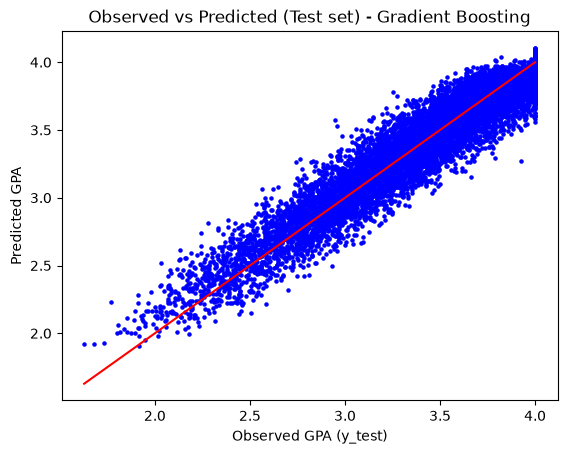

In [41]:
plt.scatter(y_test, y_pred_gb, color = 'blue', s=5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color = 'red')
plt.title('Observed vs Predicted (Test set) - Gradient Boosting')
plt.xlabel('Observed GPA (y_test)')
plt.ylabel('Predicted GPA')
plt.show()

In [44]:
a = regressor_poly.intercept_
b = regressor_poly.coef_

sample5 = X_test.sample(5, random_state=1)
X5 = poly_reg.transform(sample5)
pred_eq = a + (X5 * b).sum(axis=1)

result = pd.DataFrame({'Actual GPA': y_test.loc[sample5.index],
                       'Predicted GPA (equation)': pred_eq.round(3)})
print(result)

       Actual GPA  Predicted GPA (equation)
15703       3.829                     4.046
36552       2.493                     2.728
3461        3.115                     3.281
3568        3.554                     3.418
647         3.454                     3.381


In [63]:
a = regressor_poly.intercept_
b = regressor_poly.coef_
sample5 = X_test.sample(5, random_state=1)
X5 = poly_reg.transform(sample5)
names = list(poly_reg.get_feature_names_out(X_train.columns))

five = ['Pre_Semester_GPA', 'Weekly_GenAI_Hours', 'Traditional_Study_Hours', 'Year_of_Study', 'Prompt_Engineering_Skill']

def term(name, r):
    i = names.index(name)
    return b[i] * X5[r][i]

rows = []
for r in range(5):
    t = [term(n, r) for n in five]
    total = a + (X5[r] * b).sum()
    others = total - a - sum(t)
    student = sample5.index[r]
    rows.append([student] + [round(x, 4) for x in t] + [round(others, 4), round(total, 3), y_test.loc[student]])

table = pd.DataFrame(rows, columns=['Student', 'Pre_GPA', 'Weekly_AI', 'Study', 'Year', 'Prompt', 'Other 204', 'Predicted', 'Actual'])
print("Intercept a =", round(a, 4))
print(table.to_string(index=False))

Intercept a = 3.3782
 Student  Pre_GPA  Weekly_AI   Study    Year  Prompt  Other 204  Predicted  Actual
   15703   0.6859     0.0431 -0.0224 -0.0304  0.0070    -0.0152      4.046   3.829
   36552  -0.7342    -0.0328  0.0662  0.0396 -0.0007     0.0121      2.728   2.493
    3461  -0.1124    -0.0394  0.0626 -0.0654 -0.0085     0.0659      3.281   3.115
    3568   0.0964    -0.0388 -0.0021  0.0046  0.0070    -0.0274      3.418   3.554
     647   0.0557    -0.0023 -0.0611  0.0046 -0.0007     0.0064      3.381   3.454


In [62]:
row = 0
names = poly_reg.get_feature_names_out(X_train.columns)
vals = X5[row]
contrib = vals * b

worked = pd.DataFrame({'Term': names, 'Value (standardized)': vals.round(3), 'Coefficient': b.round(4), 'Value x Coefficient': contrib.round(4)})
worked = worked[worked['Term'] != '1']
top5 = worked.reindex(worked['Value x Coefficient'].abs().sort_values(ascending=False).index).head(5)
print(top5.to_string(index=False))
print("Intercept:", round(a, 4))
print("Sum of the other terms:", round(contrib.sum() - top5['Value x Coefficient'].sum(), 4))
print("Predicted GPA:", round(a + contrib.sum(), 3))

                   Term  Value (standardized)  Coefficient  Value x Coefficient
       Pre_Semester_GPA                 1.562       0.4392               0.6859
     Weekly_GenAI_Hours                 1.151       0.0375               0.0431
     Pre_Semester_GPA^2                 2.440      -0.0162              -0.0396
          Year_of_Study                -0.637       0.0478              -0.0304
Traditional_Study_Hours                -0.337       0.0664              -0.0224
Intercept: 3.3782
Sum of the other terms: 0.0314
Predicted GPA: 4.046


In [45]:
ai_impact['Performance_Level'] = (ai_impact['Post_Semester_GPA'] >= 3.5).astype(int)
print(ai_impact['Performance_Level'].value_counts())

Performance_Level
0    26044
1    20899
Name: count, dtype: int64


In [48]:
y_train_c = ai_impact.loc[y_train.index, 'Performance_Level']
y_test_c = ai_impact.loc[y_test.index, 'Performance_Level']

In [58]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

classifier_lr = LogisticRegression(random_state = 0)
classifier_lr.fit(X_train, y_train_c)
y_pred_lr = classifier_lr.predict(X_test)

classifier_knn = KNeighborsClassifier(n_neighbors = 5, metric = 'minkowski', p = 2)
classifier_knn.fit(X_train, y_train_c)
y_pred_knn = classifier_knn.predict(X_test)

classifier_nb = GaussianNB()
classifier_nb.fit(X_train, y_train_c)
y_pred_nb = classifier_nb.predict(X_test)

classifier_dt = DecisionTreeClassifier(criterion = 'entropy', random_state = 0)
classifier_dt.fit(X_train, y_train_c)
y_pred_dt = classifier_dt.predict(X_test)

classifier_svm = SVC(kernel = 'rbf', random_state = 0)
classifier_svm.fit(X_train, y_train_c)
y_pred_svm = classifier_svm.predict(X_test)

classifier_rf = RandomForestClassifier(n_estimators = 100, criterion = 'entropy', random_state = 0)
classifier_rf.fit(X_train, y_train_c)
y_pred_rf = classifier_rf.predict(X_test)

In [59]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

names = ['Logistic Regression', 'KNN', 'Naive Bayes', 'Decision Tree', 'SVM', 'Random Forest']
preds = [y_pred_lr, y_pred_knn, y_pred_nb, y_pred_dt, y_pred_svm, y_pred_rf]

rows = []
for name, p in zip(names, preds):
    cm = confusion_matrix(y_test_c, p)
    errors = cm[0][1] + cm[1][0]
    acc = accuracy_score(y_test_c, p)
    prec = precision_score(y_test_c, p)
    rec = recall_score(y_test_c, p)
    f1 = f1_score(y_test_c, p)
    rows.append([name, cm, errors, acc, prec, rec, f1])

results = pd.DataFrame(rows, columns=['Model', 'Confusion Matrix', 'Errors (FP+FN)', 'Accuracy', 'Precision', 'Recall', 'F1-score'])
results = results.sort_values('F1-score', ascending=False).reset_index(drop=True)
print(results)

                 Model            Confusion Matrix  Errors (FP+FN)  Accuracy  \
0                  SVM  [[4702, 484], [447, 3756]]             931  0.900841   
1        Random Forest  [[4689, 497], [457, 3746]]             954  0.898392   
2  Logistic Regression  [[4685, 501], [474, 3729]]             975  0.896155   
3          Naive Bayes  [[4527, 659], [410, 3793]]            1069  0.886143   
4                  KNN  [[4458, 728], [667, 3536]]            1395  0.851422   
5        Decision Tree  [[4515, 671], [719, 3484]]            1390  0.851954   

   Precision    Recall  F1-score  
0   0.885849  0.893647  0.889731  
1   0.882866  0.891268  0.887047  
2   0.881560  0.887223  0.884383  
3   0.851977  0.902451  0.876488  
4   0.829268  0.841304  0.835243  
5   0.838508  0.828932  0.833692  


In [51]:
import numpy as np
unique, counts = np.unique(y_pred_svm, return_counts=True)
print("Predicted by SVM (best-fit): Low =", counts[0], " High =", counts[1])
print("Actual in test set:", y_test_c.value_counts().sort_index().tolist())

Predicted by SVM (best-fit): Low = 5149  High = 4240
Actual in test set: [5186, 4203]


In [52]:
from sklearn.preprocessing import StandardScaler

X = ai_impact.iloc[:, [3, 8]].values
sc_cluster = StandardScaler()
X = sc_cluster.fit_transform(X)

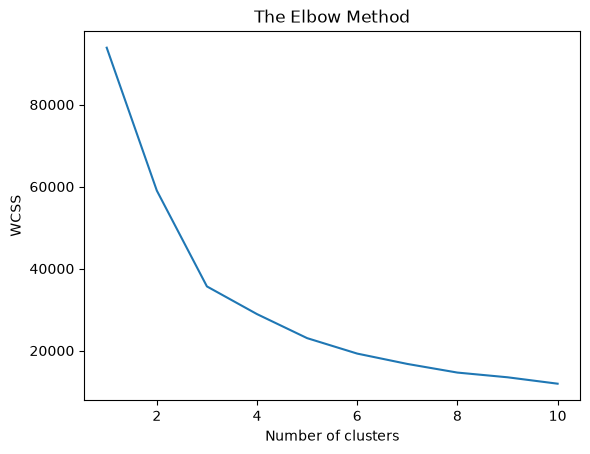

In [53]:
from sklearn.cluster import KMeans
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters = i, init = 'k-means++', random_state = 42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)
plt.plot(range(1, 11), wcss)
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

In [54]:
kmeans = KMeans(n_clusters = 3, init = 'k-means++', random_state = 42)
y_kmeans = kmeans.fit_predict(X)
print(y_kmeans)

[0 1 0 ... 0 0 2]


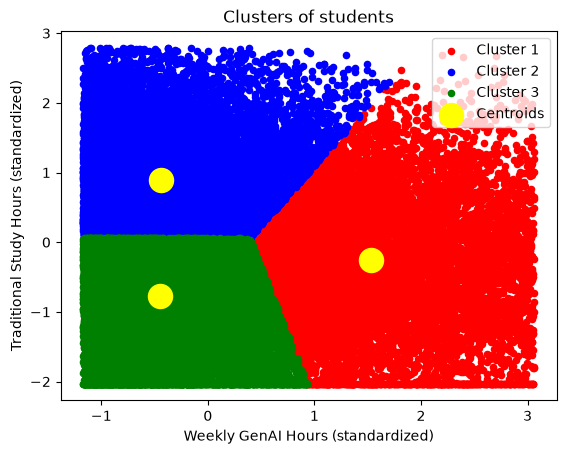

In [55]:
plt.scatter(X[y_kmeans == 0, 0], X[y_kmeans == 0, 1], s = 20, c = 'red', label = 'Cluster 1')
plt.scatter(X[y_kmeans == 1, 0], X[y_kmeans == 1, 1], s = 20, c = 'blue', label = 'Cluster 2')
plt.scatter(X[y_kmeans == 2, 0], X[y_kmeans == 2, 1], s = 20, c = 'green', label = 'Cluster 3')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s = 300, c = 'yellow', label = 'Centroids')
plt.title('Clusters of students')
plt.xlabel('Weekly GenAI Hours (standardized)')
plt.ylabel('Traditional Study Hours (standardized)')
plt.legend()
plt.show()

In [56]:
profile = ai_impact.copy()
profile['Cluster'] = y_kmeans
print(profile['Cluster'].value_counts().sort_index())
print(profile.groupby('Cluster')[['Weekly_GenAI_Hours', 'Traditional_Study_Hours', 'Anxiety_Level_During_Exams', 'Perceived_AI_Dependency', 'Post_Semester_GPA']].mean().round(2))

Cluster
0    10519
1    18576
2    17848
Name: count, dtype: int64
         Weekly_GenAI_Hours  Traditional_Study_Hours  \
Cluster                                                
0                     16.43                     9.99   
1                      4.44                    15.81   
2                      4.40                     7.34   

         Anxiety_Level_During_Exams  Perceived_AI_Dependency  \
Cluster                                                        
0                              4.93                     4.66   
1                              3.97                     2.93   
2                              3.96                     2.90   

         Post_Semester_GPA  
Cluster                     
0                     3.36  
1                     3.42  
2                     3.31  


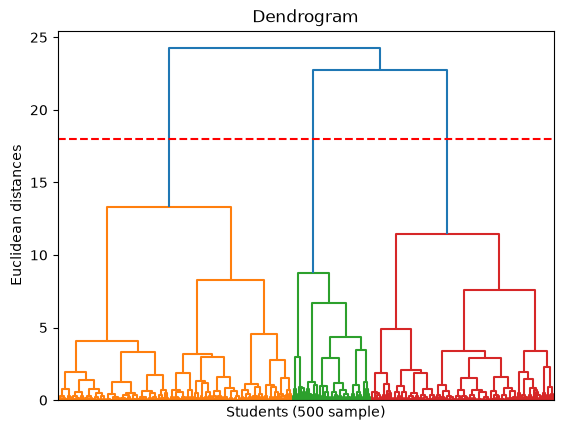

In [60]:
import scipy.cluster.hierarchy as sch

rng = np.random.RandomState(42)
idx = rng.choice(len(X), 500, replace = False)
X_sample = X[idx]

dendrogram = sch.dendrogram(sch.linkage(X_sample, method = 'ward'), no_labels = True)
plt.axhline(y = 18, color = 'red', linestyle = '--')
plt.title('Dendrogram')
plt.xlabel('Students (500 sample)')
plt.ylabel('Euclidean distances')
plt.show()

In [61]:
from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(n_clusters = 3, metric = 'euclidean', linkage = 'ward')
y_hc = hc.fit_predict(X_sample)

hc_profile = ai_impact.iloc[idx][['Weekly_GenAI_Hours', 'Traditional_Study_Hours', 'Anxiety_Level_During_Exams', 'Post_Semester_GPA']].copy()
hc_profile['Cluster'] = y_hc
print(hc_profile['Cluster'].value_counts().sort_index())
print(hc_profile.groupby('Cluster').mean().round(2))

Cluster
0    237
1    184
2     79
Name: count, dtype: int64
         Weekly_GenAI_Hours  Traditional_Study_Hours  \
Cluster                                                
0                      4.55                     7.91   
1                      5.56                    16.20   
2                     17.29                    11.27   

         Anxiety_Level_During_Exams  Post_Semester_GPA  
Cluster                                                 
0                              3.88               3.32  
1                              4.27               3.36  
2                              5.29               3.29  
